In [2]:

from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nChecking possible dataset locations:")

possible_paths = [
    Path("output/splits"),
    Path("Maternal health risk data 2/output/splits"),
    Path("../output/splits"),
    Path("../Maternal health risk data 2/output/splits"),
]

for path in possible_paths:
    print(
        "FOUND" if (path / "train.csv").is_file() else "NOT FOUND",
        "->",
        path.resolve()
    )


Current working directory:
/Users/hgianee/Downloads/Maternal health risk data 2/output

Checking possible dataset locations:
NOT FOUND -> /Users/hgianee/Downloads/Maternal health risk data 2/output/output/splits
NOT FOUND -> /Users/hgianee/Downloads/Maternal health risk data 2/output/Maternal health risk data 2/output/splits
FOUND -> /Users/hgianee/Downloads/Maternal health risk data 2/output/splits
NOT FOUND -> /Users/hgianee/Downloads/Maternal health risk data 2/Maternal health risk data 2/output/splits


In [3]:

# Chạy một lần nếu chưa cài
%pip install -q numpy pandas matplotlib scipy scikit-learn shap joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json
import shap

from pathlib import Path
from scipy.optimize import minimize_scalar
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    log_loss, accuracy_score, f1_score
)

SEED = 42
LABELS = ["Low", "Mid", "High"]
LABEL_TO_INT = {v: i for i, v in enumerate(LABELS)}

BASIC = [
    "Age", "BodyTemp", "HeartRate",
    "SystolicBP", "DiastolicBP", "BMI"
]
FULL = BASIC + ["HbA1c", "FastingGlucose"]

DATA_DIR = Path("splits")      
RESULT_DIR = Path("output/section_4_5")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

data = {
    name: pd.read_csv(DATA_DIR / f"{name}.csv")
    for name in ["train", "calibration", "policy_val", "test"]
}

for name, df in data.items():
    assert set(FULL + ["row_id", "RiskLevel"]).issubset(df.columns)
    assert set(df["RiskLevel"].unique()) == set(LABELS)
    assert df["row_id"].is_unique
    print(f"{name:12s}: {len(df)} records")

print("\nDATA LOADED SUCCESSFULLY!")


Note: you may need to restart the kernel to use updated packages.
train       : 3634 records
calibration : 606 records
policy_val  : 606 records
test        : 1212 records

DATA LOADED SUCCESSFULLY!


In [4]:

MODEL_DIR = Path("models")

basic_path = MODEL_DIR / "basic_model.joblib"
full_path = MODEL_DIR / "full_model.joblib"

if basic_path.exists() and full_path.exists():
    # Official models from Section 4.1
    models = {
        "basic": joblib.load(basic_path),
        "full": joblib.load(full_path)
    }
    model_mode = "OFFICIAL"
else:
    print("Official models unavailable.")
    print("Training DEMO Random Forest models...")

    models = {}

    for name, columns in {
        "basic": BASIC,
        "full": FULL
    }.items():

        clf = RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=SEED,
            n_jobs=-1
        )

        clf.fit(
            data["train"][columns],
            data["train"]["RiskLevel"]
        )

        models[name] = clf

    model_mode = "DEMO"

print("Model mode:", model_mode)
print("Basic:", type(models["basic"]).__name__)
print("Full:", type(models["full"]).__name__)


Official models unavailable.
Training DEMO Random Forest models...
Model mode: DEMO
Basic: RandomForestClassifier
Full: RandomForestClassifier


In [5]:

def get_model_classes(model):
    classes = list(model.classes_)
    normalized = []

    for c in classes:
        if isinstance(c, (int, np.integer)):
            normalized.append(LABELS[int(c)])
        elif isinstance(c, (float, np.floating)) and float(c).is_integer():
            normalized.append(LABELS[int(c)])
        else:
            normalized.append(str(c))

    return normalized


def get_probs(model, df, features):
    probs = np.asarray(
        model.predict_proba(df[features]),
        dtype=float
    )

    classes = get_model_classes(model)

    assert set(classes) == set(LABELS), (
        f"Unexpected classes: {classes}"
    )

    indices = [classes.index(c) for c in LABELS]
    probs = probs[:, indices]

    assert probs.shape == (len(df), 3)
    assert np.allclose(probs.sum(axis=1), 1)

    return probs


def temperature_scale(probs, temperature):
    logits = np.log(
        np.clip(probs, 1e-12, 1.0)
    ) / temperature

    logits = logits - logits.max(
        axis=1, keepdims=True
    )

    exp_logits = np.exp(logits)

    return exp_logits / exp_logits.sum(
        axis=1, keepdims=True
    )


def fit_temperature(probs, y_true):
    y = pd.Series(y_true).map(
        LABEL_TO_INT
    ).to_numpy()

    result = minimize_scalar(
        lambda t: log_loss(
            y,
            temperature_scale(probs, t),
            labels=[0, 1, 2]
        ),
        bounds=(0.3, 5.0),
        method="bounded"
    )

    return float(result.x)


feature_sets = {
    "basic": BASIC,
    "full": FULL
}

temperatures = {}

for name, features in feature_sets.items():
    model = models[name]

    cal_probs = get_probs(
        model,
        data["calibration"],
        features
    )

    T = fit_temperature(
        cal_probs,
        data["calibration"]["RiskLevel"]
    )

    temperatures[name] = T

    print(f"{name.upper()} Temperature: {T:.4f}")

with open(
    RESULT_DIR / "temperatures.json",
    "w"
) as f:
    json.dump({
        "model_mode": model_mode,
        "temperatures": temperatures
    }, f, indent=2)

print("CALIBRATION FITTED!")


BASIC Temperature: 0.9225
FULL Temperature: 0.4432
CALIBRATION FITTED!


In [6]:

def multiclass_brier(y_true, probs):
    y = pd.Series(y_true).map(
        LABEL_TO_INT
    ).to_numpy()

    one_hot = np.eye(3)[y]

    return float(
        np.mean(np.sum((probs - one_hot) ** 2, axis=1))
    )


def high_risk_ece(y_true, probs, bins=10):
    actual = (
        np.asarray(y_true) == "High"
    ).astype(int)

    p_high = probs[:, 2]

    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0

    for i in range(bins):
        if i == bins - 1:
            mask = (
                (p_high >= edges[i]) &
                (p_high <= edges[i + 1])
            )
        else:
            mask = (
                (p_high >= edges[i]) &
                (p_high < edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        observed = actual[mask].mean()
        predicted = p_high[mask].mean()

        ece += (
            mask.mean() *
            abs(observed - predicted)
        )

    return float(ece)


def calculate_metrics(y_true, probs):
    y_num = pd.Series(y_true).map(
        LABEL_TO_INT
    ).to_numpy()

    predictions = np.argmax(probs, axis=1)

    return {
        "Brier": multiclass_brier(y_true, probs),
        "LogLoss": log_loss(
            y_num, probs, labels=[0, 1, 2]
        ),
        "HighRisk_ECE": high_risk_ece(
            y_true, probs
        ),
        "Accuracy": accuracy_score(
            y_num, predictions
        ),
        "Macro_F1": f1_score(
            y_num, predictions, average="macro"
        )
    }


metric_rows = []
predictions = {}

for name, features in feature_sets.items():
    model = models[name]
    T = temperatures[name]

    # Export probabilities for downstream experiments
    for split_name in ["policy_val", "test"]:
        df_split = data[split_name]

        raw_probs = get_probs(
            model, df_split, features
        )

        calibrated = temperature_scale(
            raw_probs, T
        )

        predictions[(name, split_name)] = {
            "raw": raw_probs,
            "calibrated": calibrated
        }

        out = pd.DataFrame({
            "row_id": df_split["row_id"].to_numpy(),
            "p_Low": calibrated[:, 0],
            "p_Mid": calibrated[:, 1],
            "p_High": calibrated[:, 2]
        })

        out.to_csv(
            RESULT_DIR / f"{name}_{split_name}_probs.csv",
            index=False
        )

    # Final reliability evaluation on TEST
    y_test = data["test"]["RiskLevel"]

    for stage in ["raw", "calibrated"]:
        probs = predictions[(name, "test")][stage]

        metrics = calculate_metrics(
            y_test, probs
        )

        metric_rows.append({
            "Model": name,
            "Stage": stage,
            **metrics
        })

metrics_df = pd.DataFrame(metric_rows)

display(metrics_df.round(4))

metrics_df.to_csv(
    RESULT_DIR / "calibration_metrics.csv",
    index=False
)


,Model,Stage,Brier,LogLoss,HighRisk_ECE,Accuracy,Macro_F1
0,basic,raw,0.1636,0.2642,0.0520,0.8705,0.8697
1,basic,calibrated,0.1655,0.2656,0.0514,0.8705,0.8697
2,full,raw,0.0345,0.0897,0.0601,0.9926,0.9926
3,full,calibrated,0.0167,0.0383,0.0117,0.9926,0.9926


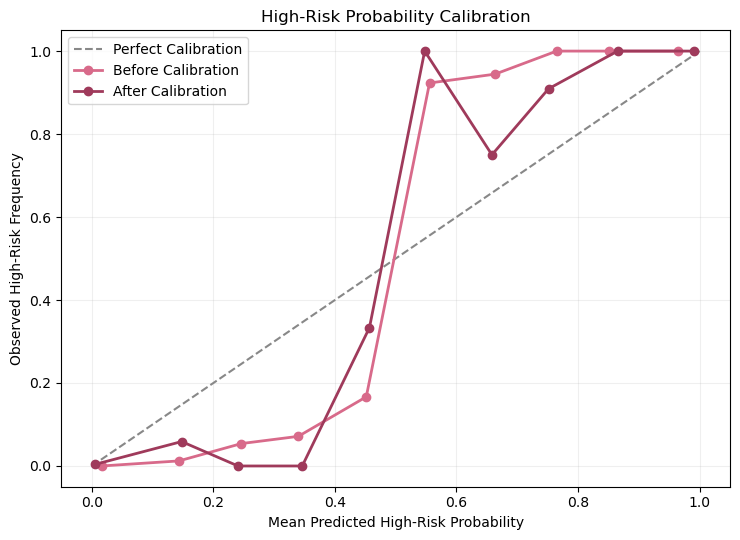

In [7]:

def reliability_points(y_true, p_high, bins=10):
    actual = (
        np.asarray(y_true) == "High"
    ).astype(float)

    edges = np.linspace(0, 1, bins + 1)

    xs, ys = [], []

    for i in range(bins):
        if i == bins - 1:
            mask = (
                (p_high >= edges[i]) &
                (p_high <= edges[i + 1])
            )
        else:
            mask = (
                (p_high >= edges[i]) &
                (p_high < edges[i + 1])
            )

        if mask.sum() > 0:
            xs.append(p_high[mask].mean())
            ys.append(actual[mask].mean())

    return xs, ys


full_test = predictions[("full", "test")]

plt.figure(figsize=(7.5, 5.5))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="#888888",
    label="Perfect Calibration"
)

for stage, color, label in [
    ("raw", "#D86A8A", "Before Calibration"),
    ("calibrated", "#9F3A5B", "After Calibration")
]:
    x, y = reliability_points(
        data["test"]["RiskLevel"],
        full_test[stage][:, 2]
    )

    plt.plot(
        x, y,
        marker="o",
        linewidth=2,
        color=color,
        label=label
    )

plt.xlabel("Mean Predicted High-Risk Probability")
plt.ylabel("Observed High-Risk Frequency")
plt.title("High-Risk Probability Calibration")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "calibration_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,count,mean,median
Correct,,,
False,9,0.3691,0.4321
True,1203,0.0487,0.0017


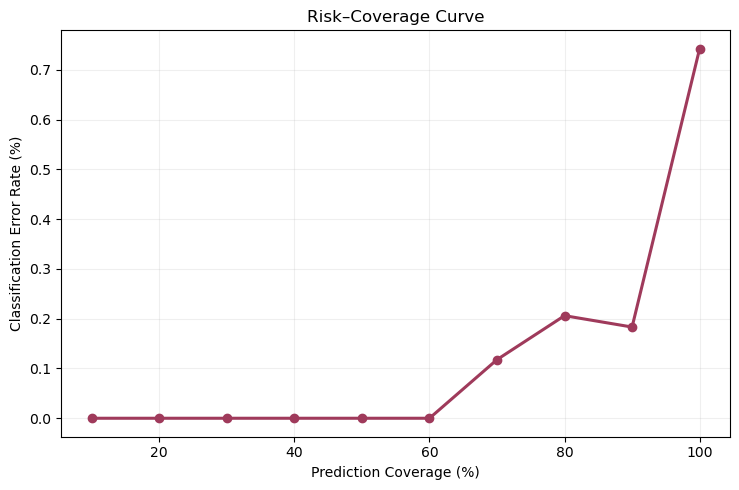

In [8]:

probs = predictions[("full", "test")]["calibrated"]

y_true = data["test"]["RiskLevel"].map(
    LABEL_TO_INT
).to_numpy()

y_pred = np.argmax(probs, axis=1)

# Normalized predictive entropy
entropy = -np.sum(
    probs * np.log(np.clip(probs, 1e-12, 1)),
    axis=1
) / np.log(3)

# Thống kê độ bất định
uncertainty_df = pd.DataFrame({
    "row_id": data["test"]["row_id"].to_numpy(),
    "TrueClass": data["test"]["RiskLevel"].to_numpy(),
    "PredictedClass": np.array(LABELS)[y_pred],
    "Entropy": entropy,
    "Correct": y_true == y_pred
})

display(
    uncertainty_df.groupby("Correct")["Entropy"]
    .agg(["count", "mean", "median"])
    .round(4)
)

uncertainty_df.to_csv(
    RESULT_DIR / "uncertainty_test.csv",
    index=False
)

# Risk-Coverage
order = np.argsort(entropy)

coverage_values = np.arange(
    0.1, 1.01, 0.1
)

risk_values = []

for coverage in coverage_values:
    n = max(1, int(np.ceil(
        len(y_true) * coverage
    )))

    selected = order[:n]

    error_rate = np.mean(
        y_pred[selected] != y_true[selected]
    )

    risk_values.append(error_rate)

plt.figure(figsize=(7.5, 5))

plt.plot(
    coverage_values * 100,
    np.array(risk_values) * 100,
    marker="o",
    color="#9F3A5B",
    linewidth=2.2
)

plt.xlabel("Prediction Coverage (%)")
plt.ylabel("Classification Error Rate (%)")
plt.title("Risk–Coverage Curve")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "risk_coverage_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Using TreeExplainer


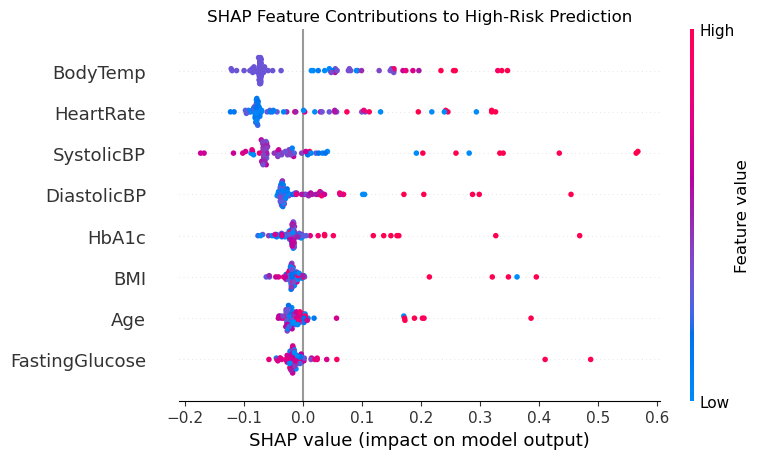

In [9]:

full_model = models["full"]

# Chọn mẫu có seed cố định để giải thích
X_explain = data["test"][FULL].sample(
    n=min(80, len(data["test"])),
    random_state=SEED
)

try:
    # Fast SHAP for tree-based models
    explainer = shap.TreeExplainer(full_model)
    shap_values = explainer(X_explain)

    values = shap_values.values

    if values.ndim != 3:
        raise ValueError("Unexpected multiclass SHAP shape.")

    high_index = get_model_classes(
        full_model
    ).index("High")

    shap_high = shap_values[:, :, high_index]

    print("Using TreeExplainer")

except Exception as exc:
    print("Using model-agnostic SHAP:", exc)

    # Explain P(High) of the fitted base model
    def predict_high(x):
        df_x = pd.DataFrame(x, columns=FULL)
        return get_probs(
            full_model, df_x, FULL
        )[:, 2]

    background = data["train"][FULL].sample(
        n=min(30, len(data["train"])),
        random_state=SEED
    )

    explainer = shap.Explainer(
        predict_high,
        masker=shap.maskers.Independent(background),
        algorithm="permutation"
    )

    shap_high = explainer(
        X_explain,
        max_evals=2 * len(FULL) + 1
    )

# Global SHAP summary
shap.plots.beeswarm(
    shap_high,
    max_display=8,
    show=False
)

plt.title("SHAP Feature Contributions to High-Risk Prediction")
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


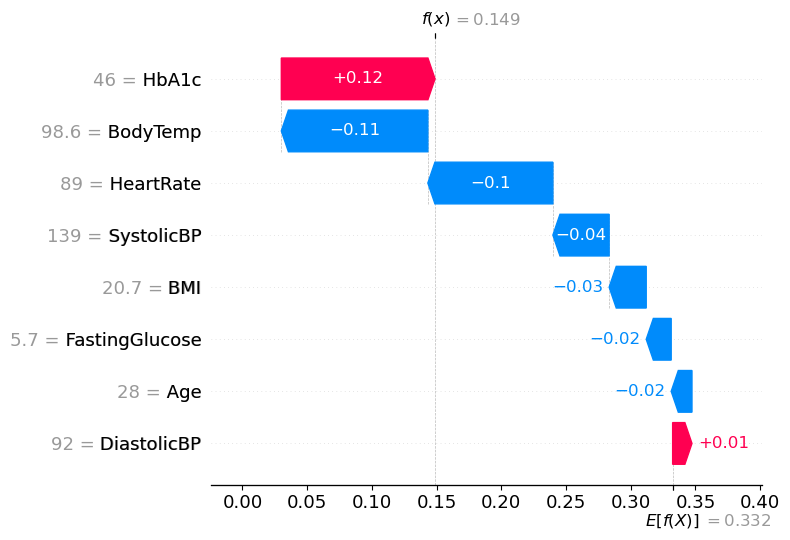

Explained row: 801

Clinical values:


,Age,BodyTemp,HeartRate,SystolicBP,DiastolicBP,BMI,HbA1c,FastingGlucose
801,28,98.6,89,139,92,20.7,46,5.7


In [10]:

# Chọn một trường hợp trong mẫu đã giải thích
case_index = 0

shap.plots.waterfall(
    shap_high[case_index],
    max_display=8,
    show=False
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "shap_local_case.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Explained row:", X_explain.index[case_index])
print("\nClinical values:")
display(X_explain.iloc[[case_index]])


In [11]:

# CELL 9 — Check High-Risk Calibration Bin Counts

import pandas as pd
import numpy as np

p = predictions[("full", "test")]["calibrated"][:, 2]
y = (data["test"]["RiskLevel"] == "High").astype(int).to_numpy()

edges = np.linspace(0, 1, 11)
rows = []

for i in range(10):
    left, right = edges[i], edges[i + 1]

    mask = (
        (p >= left) &
        ((p <= right) if i == 9 else (p < right))
    )

    rows.append({
        "Probability_Bin": f"{left:.1f}–{right:.1f}",
        "N_Records": int(mask.sum()),
        "Mean_Predicted": round(float(p[mask].mean()), 4)
            if mask.any() else np.nan,
        "Observed_High_Rate": round(float(y[mask].mean()), 4)
            if mask.any() else np.nan
    })

bin_table = pd.DataFrame(rows)

display(bin_table)

bin_table.to_csv(
    RESULT_DIR / "calibration_bin_counts.csv",
    index=False
)

print("Model mode:", model_mode)
print("Total records:", bin_table["N_Records"].sum())
print("Sparse bins (<20 records):",
      int((bin_table["N_Records"] < 20).sum()))


,Probability_Bin,N_Records,Mean_Predicted,Observed_High_Rate
0,0.0–0.1,785,0.0052,0.0038
1,0.1–0.2,17,0.1478,0.0588
2,0.2–0.3,4,0.2405,0.0000
3,0.3–0.4,3,0.3462,0.0000
4,0.4–0.5,3,0.4568,0.3333
5,0.5–0.6,4,0.5477,1.0000
6,0.6–0.7,4,0.6583,0.7500
7,0.7–0.8,11,0.7514,0.9091
8,0.8–0.9,12,0.8651,1.0000
9,0.9–1.0,369,0.9901,1.0000


Model mode: DEMO
Total records: 1212
Sparse bins (<20 records): 8


BEFORE CALIBRATION


,bin,N_Records,Mean_Predicted,Observed_Rate
0,"(-0.001, 0.0025]",263,0.000685,0.000000
1,"(0.0025, 0.0164]",222,0.007036,0.000000
2,"(0.0164, 0.158]",242,0.066138,0.004132
3,"(0.158, 0.913]",242,0.603127,0.657025
4,"(0.913, 1.0]",243,0.967294,1.000000


AFTER CALIBRATION


,bin,N_Records,Mean_Predicted,Observed_Rate
0,"(-0.001, 1.36e-06]",243,2.094536e-07,0.000000
1,"(1.36e-06, 0.000104]",242,1.838764e-05,0.000000
2,"(0.000104, 0.0228]",242,4.467745e-03,0.004132
3,"(0.0228, 0.995]",242,6.403897e-01,0.657025
4,"(0.995, 1.0]",243,9.990432e-01,1.000000


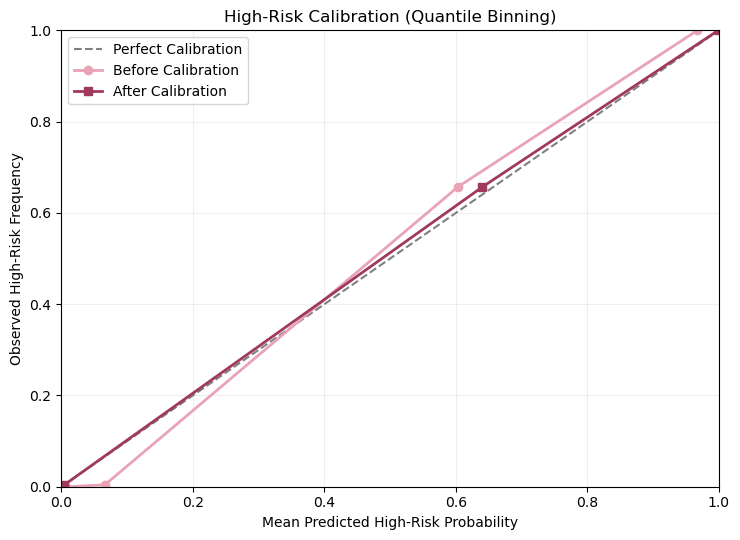

In [12]:

# CELL 10 — Equal-Frequency Calibration Plot
# Descriptive visualization only (not model selection)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y_true = (
    data["test"]["RiskLevel"] == "High"
).astype(int).to_numpy()

raw_p = predictions[("full", "test")]["raw"][:, 2]
cal_p = predictions[("full", "test")]["calibrated"][:, 2]


def make_quantile_bins(probabilities, actual, q=5):
    temp = pd.DataFrame({
        "prob": probabilities,
        "actual": actual
    })

    temp["bin"] = pd.qcut(
        temp["prob"],
        q=q,
        duplicates="drop"
    )

    summary = (
        temp.groupby("bin", observed=True)
        .agg(
            N_Records=("actual", "size"),
            Mean_Predicted=("prob", "mean"),
            Observed_Rate=("actual", "mean")
        )
        .reset_index()
    )

    return summary


before = make_quantile_bins(raw_p, y_true)
after = make_quantile_bins(cal_p, y_true)

print("BEFORE CALIBRATION")
display(before)

print("AFTER CALIBRATION")
display(after)

fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Perfect Calibration"
)

ax.plot(
    before["Mean_Predicted"],
    before["Observed_Rate"],
    "o-",
    color="#E9A3B7",
    linewidth=2,
    label="Before Calibration"
)

ax.plot(
    after["Mean_Predicted"],
    after["Observed_Rate"],
    "s-",
    color="#9F3A5B",
    linewidth=2,
    label="After Calibration"
)

ax.set(
    xlabel="Mean Predicted High-Risk Probability",
    ylabel="Observed High-Risk Frequency",
    title="High-Risk Calibration (Quantile Binning)"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "calibration_quantile.png",
    dpi=300,
    bbox_inches="tight"
)

after.to_csv(
    RESULT_DIR / "calibration_quantile_bins.csv",
    index=False
)

plt.show()
